In [5]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn google-genai

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [7]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving all-data.csv to all-data.csv
Uploaded files: ['all-data.csv']


In [8]:
import os

print("Files in the working directory:")
print(os.listdir("/content"))

Files in the working directory:
['.config', 'drive', 'all-data.csv', 'sample_data']


In [9]:
# Load the raw dataset
df = pd.read_csv(
    "/content/all-data.csv",
    encoding="latin-1",
    header=None,
    names=["sentiment", "text"]
)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (4846, 2)

First 5 rows:


,sentiment,text
0,neutral,"According to Gran , the company has no plans t..."
1,neutral,Technopolis plans to develop in stages an area...
2,negative,The international electronic industry company ...
3,positive,With the new production plant the company woul...
4,positive,According to the company 's updated strategy f...



Column names:
['sentiment', 'text']

Data types:
sentiment    object
text         object
dtype: object

Missing values:
sentiment    0
text         0
dtype: int64


In [10]:
print("Sentiment distribution:")
print(df["sentiment"].value_counts(dropna=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nEmpty or whitespace-only sentences:")
print(
    df["text"].isna().sum()
    + df["text"].fillna("").str.strip().eq("").sum()
)

print("\nSample sentences:")
for _, row in df.sample(min(5, len(df)), random_state=42).iterrows():
    print(f"\nSentiment: {row['sentiment']}")
    print(f"Text: {row['text']}")

Sentiment distribution:
sentiment
neutral     2879
positive    1363
negative     604
Name: count, dtype: int64

Duplicate rows: 6

Empty or whitespace-only sentences:
0

Sample sentences:

Sentiment: neutral
Text: The company was supposed to deliver machinery to a veneer mill in the Tomsk region , in Russia .

Sentiment: neutral
Text: UNC Charlotte would also deploy SSH Tectia Connector to enable secure application connectivity .

Sentiment: neutral
Text: In 2009 , Lee & Man had a combined annual production capacity of close to 4.5 million tonnes of paper and 300,000 tonnes of pulp .

Sentiment: neutral
Text: `` That 's a very high figure on the European scale , '' Noop said , recalling however that this also includes beer bought by Finnish tourists .

Sentiment: neutral
Text: In Finland , the corresponding service is Alma Media 's Etuovi.com , Finland 's most popular and best known nationwide online service for home and property sales .


In [11]:
# Display every exact duplicate row, including its first occurrence
duplicate_mask = df.duplicated(keep=False)

duplicate_rows = (
    df.loc[duplicate_mask]
      .sort_values(["sentiment", "text"])
)

print("Rows involved in exact duplicates:", len(duplicate_rows))
display(duplicate_rows)

Rows involved in exact duplicates: 12


,sentiment,text
2395,neutral,Ahlstrom 's share is quoted on the NASDAQ OMX ...
2396,neutral,Ahlstrom 's share is quoted on the NASDAQ OMX ...
3093,neutral,Proha Plc ( Euronext :7327 ) announced today (...
3094,neutral,Proha Plc ( Euronext :7327 ) announced today (...
2566,neutral,SSH Communications Security Corporation is hea...
2567,neutral,SSH Communications Security Corporation is hea...
3205,neutral,The company serves customers in various indust...
3206,neutral,The company serves customers in various indust...
1098,neutral,The issuer is solely responsible for the conte...
1099,neutral,The issuer is solely responsible for the conte...


In [12]:
# Preserve the original dataframe for reference
df_raw = df.copy()

# Conservative text and label normalization
df["sentiment"] = df["sentiment"].str.strip().str.lower()
df["text"] = df["text"].str.strip()

# Remove missing and empty records
df = df.dropna(subset=["sentiment", "text"])
df = df[
    df["text"].ne("") &
    df["sentiment"].ne("")
].copy()

# Remove exact duplicate sentence-label records
df = df.drop_duplicates(
    subset=["sentiment", "text"]
).reset_index(drop=True)

# Validate expected labels
expected_labels = {"positive", "negative", "neutral"}

assert set(df["sentiment"].unique()) == expected_labels
assert df["text"].notna().all()
assert df["text"].str.len().gt(0).all()
assert not df.duplicated(subset=["sentiment", "text"]).any()

print("Cleaned dataset shape:", df.shape)
print("\nClass distribution:")
print(df["sentiment"].value_counts())

print("\nRemaining missing values:")
print(df.isna().sum())

print("\nRemaining duplicate sentence-label pairs:",
      df.duplicated(subset=["sentiment", "text"]).sum())

Cleaned dataset shape: (4840, 2)

Class distribution:
sentiment
neutral     2873
positive    1363
negative     604
Name: count, dtype: int64

Remaining missing values:
sentiment    0
text         0
dtype: int64

Remaining duplicate sentence-label pairs: 0


In [13]:
# Find sentences associated with more than one sentiment label
label_counts_per_text = df.groupby("text")["sentiment"].nunique()

conflicting_texts = label_counts_per_text[
    label_counts_per_text > 1
].index

conflicts_df = (
    df[df["text"].isin(conflicting_texts)]
    .sort_values("text")
)

print("Number of sentences with conflicting labels:",
      len(conflicting_texts))

print("Number of rows involved in conflicts:",
      len(conflicts_df))


Number of sentences with conflicting labels: 2
Number of rows involved in conflicts: 4


In [14]:
# Create a temporary comparison key; do not modify the actual text
normalized_text = (
    df["text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

normalized_groups = df.assign(
    _normalized_text=normalized_text
)

normalized_conflicts = (
    normalized_groups.groupby("_normalized_text")["sentiment"]
    .nunique()
)

normalized_conflicts = normalized_conflicts[
    normalized_conflicts > 1
]

print(
    "Whitespace-normalized sentences with conflicting labels:",
    len(normalized_conflicts)
)

Whitespace-normalized sentences with conflicting labels: 2


In [15]:
# Remove sentences that have more than one sentiment label
df_model = df[~df["text"].isin(conflicting_texts)].copy()

df_model = df_model.reset_index(drop=True)

print("Original cleaned dataset:", df.shape)
print("Dataset after conflict removal:", df_model.shape)

print("\nClass distribution:")
print(df_model["sentiment"].value_counts())

print("\nClass proportions:")
print(
    (df_model["sentiment"].value_counts(normalize=True) * 100)
    .round(2)
)

Original cleaned dataset: (4840, 2)
Dataset after conflict removal: (4836, 2)

Class distribution:
sentiment
neutral     2871
positive    1361
negative     604
Name: count, dtype: int64

Class proportions:
sentiment
neutral     59.37
positive    28.14
negative    12.49
Name: proportion, dtype: float64


In [16]:
# Normalize whitespace for duplicate detection only
normalized_text = (
    df_model["text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df_model = df_model.assign(
    _normalized_text=normalized_text
)

print(
    "Rows with repeated normalized text:",
    df_model.duplicated(
        subset=["_normalized_text"],
        keep=False
    ).sum()
)

print(
    "Unique normalized sentences:",
    df_model["_normalized_text"].nunique()
)

print(
    "Rows with conflicting labels remaining:",
    (
        df_model.groupby("_normalized_text")["sentiment"]
        .nunique()
        .gt(1)
        .sum()
    )
)

Rows with repeated normalized text: 0
Unique normalized sentences: 4836
Rows with conflicting labels remaining: 0


In [17]:
# Count words in each financial sentence
df_model["word_count"] = df_model["text"].apply(
    lambda sentence: len(sentence.split())
)

# Count characters
df_model["char_count"] = df_model["text"].str.len()

# View statistical summary
display(
    df_model.groupby("sentiment")[
        ["word_count", "char_count"]
    ].describe().round(2)
)

word_count                                            char_count  \
               count   mean    std  min   25%   50%   75%   max      count   
sentiment                                                                    
negative       604.0  23.92   9.89  5.0  17.0  22.0  30.0  56.0      604.0   
neutral       2871.0  22.15   9.78  2.0  15.0  21.0  28.0  81.0     2871.0   
positive      1361.0  24.68  10.06  5.0  17.0  23.0  31.0  57.0     1361.0   

                                                           
             mean    std   min   25%    50%    75%    max  
sentiment                                                  
negative   125.76  52.90  37.0  85.0  118.0  157.0  296.0  
neutral    124.94  56.86   9.0  81.0  116.0  161.0  315.0  
positive   135.60  56.24  24.0  91.0  128.0  175.0  298.0

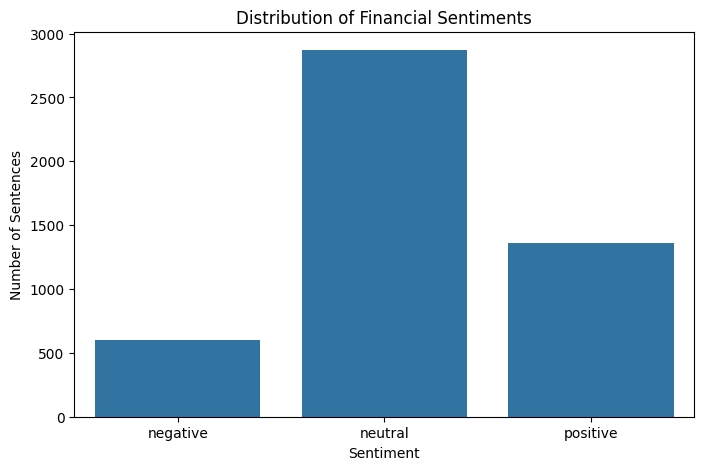

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_model,
    x="sentiment",
    order=["negative", "neutral", "positive"]
)

plt.title("Distribution of Financial Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Sentences")
plt.show()

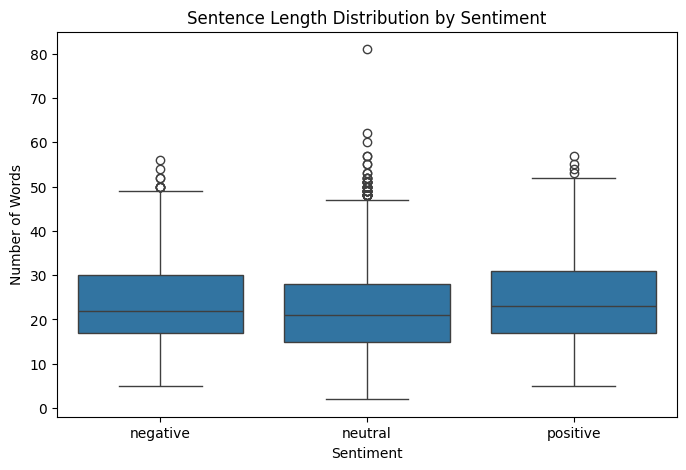

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_model,
    x="sentiment",
    y="word_count",
    order=["negative", "neutral", "positive"]
)

plt.title("Sentence Length Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.show()

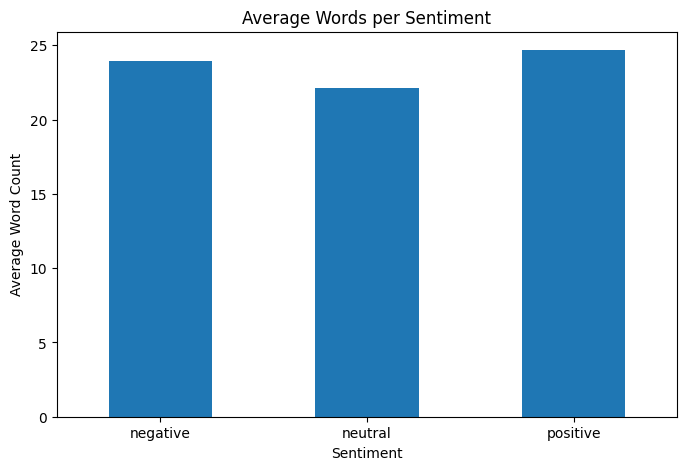

In [20]:
average_words = (
    df_model.groupby("sentiment")["word_count"]
    .mean()
    .reindex(["negative", "neutral", "positive"])
)

average_words.plot(kind="bar", figsize=(8, 5))

plt.title("Average Words per Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Word Count")
plt.xticks(rotation=0)
plt.show()

In [21]:
# First split: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    df_model,
    test_size=0.20,
    random_state=42,
    stratify=df_model["sentiment"]
)

# Second split: divide temporary data equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["sentiment"]
)

print("Training set:", train_df.shape)
print("Validation set:", val_df.shape)
print("Test set:", test_df.shape)

Training set: (3868, 5)
Validation set: (484, 5)
Test set: (484, 5)


In [22]:
#verify the distributions
for name, split in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} set")
    print(
        (split["sentiment"].value_counts(normalize=True) * 100)
        .round(2)
    )


Training set
sentiment
neutral     59.36
positive    28.15
negative    12.49
Name: proportion, dtype: float64

Validation set
sentiment
neutral     59.5
positive    28.1
negative    12.4
Name: proportion, dtype: float64

Test set
sentiment
neutral     59.3
positive    28.1
negative    12.6
Name: proportion, dtype: float64


In [23]:
#verify to text leakage
train_texts = set(train_df["_normalized_text"])
val_texts = set(val_df["_normalized_text"])
test_texts = set(test_df["_normalized_text"])

print("Train-validation overlap:", len(train_texts & val_texts))
print("Train-test overlap:", len(train_texts & test_texts))
print("Validation-test overlap:", len(val_texts & test_texts))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


# Parameter-Efficient Fine-Tuning (PEFT) using QLoRA with 4-bit quantization.

In [24]:
import torch
import pandas as pd

# 1. GPU verification
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory / 1024**3
    )
    print(f"GPU memory: {gpu_memory:.2f} GB")
else:
    print("GPU not detected. Please check your runtime.")

# 2. Dataset split verification
print("\nDataset split sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

# 3. Column verification
print("\nColumns:", train_df.columns.tolist())

# 4. Class distribution
print("\nTraining class distribution:")
print(train_df["sentiment"].value_counts())

print("\nValidation class distribution:")
print(val_df["sentiment"].value_counts())

print("\nTest class distribution:")
print(test_df["sentiment"].value_counts())

CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

Dataset split sizes:
Training: 3868
Validation: 484
Testing: 484

Columns: ['sentiment', 'text', '_normalized_text', 'word_count', 'char_count']

Training class distribution:
sentiment
neutral     2296
positive    1089
negative     483
Name: count, dtype: int64

Validation class distribution:
sentiment
neutral     288
positive    136
negative     60
Name: count, dtype: int64

Test class distribution:
sentiment
neutral     287
positive    136
negative     61
Name: count, dtype: int64


In [25]:
train_df.to_csv("/content/train_split.csv", index=False)
val_df.to_csv("/content/val_split.csv", index=False)
test_df.to_csv("/content/test_split.csv", index=False)

print("All three dataset splits saved!")

All three dataset splits saved!


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [27]:
import os

print(os.path.exists("/content/drive/MyDrive"))

True


In [28]:
import os
import shutil

backup_dir = "/content/drive/MyDrive/QLoRA_Backup"
os.makedirs(backup_dir, exist_ok=True)

for filename, dataframe in [
    ("train_split.csv", train_df),
    ("val_split.csv", val_df),
    ("test_split.csv", test_df)
]:
    dataframe.to_csv(
        os.path.join(backup_dir, filename),
        index=False
    )

print("All three splits successfully backed up!")

All three splits successfully backed up!


In [29]:
print(os.listdir(backup_dir))

['train_split.csv', 'val_split.csv', 'test_split.csv']


In [2]:
import torch
import pandas as pd
import os

backup_dir = "/content/drive/MyDrive/QLoRA_Backup"

train_df = pd.read_csv(f"{backup_dir}/train_split.csv")
val_df = pd.read_csv(f"{backup_dir}/val_split.csv")
test_df = pd.read_csv(f"{backup_dir}/test_split.csv")

print("GPU:", torch.cuda.get_device_name(0))
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

GPU: Tesla T4
Train: (3868, 5)
Validation: (484, 5)
Test: (484, 5)


In [3]:
import torch
import pandas as pd
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Pandas: 2.2.3
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [4]:
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTraining labels:")
print(train_df["sentiment"].value_counts())

Train: (3868, 5)
Validation: (484, 5)
Test: (484, 5)

Training labels:
sentiment
neutral     2296
positive    1089
negative     483
Name: count, dtype: int64


In [5]:
import importlib.metadata as metadata

packages = [
    "torch",
    "transformers",
    "accelerate",
    "bitsandbytes",
    "peft",
    "datasets",
    "numpy",
    "pandas",
    "pyarrow"
]

for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: Not installed")

torch: 2.11.0+cu130
transformers: 5.22.0
accelerate: 1.15.0
bitsandbytes: Not installed
peft: 0.21.2
datasets: 4.8.5
numpy: 2.4.6
pandas: 2.2.3
pyarrow: 23.0.1


In [6]:
!pip install -q --no-deps bitsandbytes

In [7]:
import torch
import bitsandbytes as bnb

print("PyTorch CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))
print("Bitsandbytes:", bnb.__version__)

print("\n4-bit quantization classes:")
print(bnb.nn.Linear4bit)

PyTorch CUDA: 13.0
GPU: Tesla T4
Bitsandbytes: 0.50.2

4-bit quantization classes:
<class 'bitsandbytes.nn.modules.Linear4bit'>


**Qwen2.5-0.5B-Instruct.**

Small enough to experiment with on a T4.



Open weights and free to download.



Suitable for instruction-following tasks.



We can adapt it to our three-class financial sentiment task.

In [8]:
#loading tokenizer
from transformers import AutoTokenizer

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.vocab_size)
print("EOS token:", tokenizer.eos_token)
print("PAD token:", tokenizer.pad_token)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Tokenizer loaded successfully!
Vocabulary size: 151643
EOS token: <|im_end|>
PAD token: <|endoftext|>


**Configure 4-bit quantization**


Normally, model weights consume substantial GPU memory. We'll load the base model using 4-bit NormalFloat (NF4) quantization.

using three settings:
1. load_in_4bit=True – store base model weights in 4-bit format.
2. bnb_4bit_quant_type="nf4" – use NormalFloat 4-bit quantization, designed for normally distributed weights.
3. bnb_4bit_use_double_quant=True – quantize the quantization constants too, saving additional memory.

using FP16 for computation on T4.


4-bit refers to how the base model weights are stored, not necessarily every computation. The calculations will use FP16.

In [9]:
import torch
from transformers import BitsAndBytesConfig

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

print("4-bit NF4 quantization configuration created!")
print(quantization_config)

4-bit NF4 quantization configuration created!
BitsAndBytesConfig {
  "_load_in_4bit": true,
  "_load_in_8bit": false,
  "bnb_4bit_compute_dtype": "float16",
  "bnb_4bit_quant_storage": "uint8",
  "bnb_4bit_quant_type": "nf4",
  "bnb_4bit_use_double_quant": true,
  "llm_int8_enable_fp32_cpu_offload": false,
  "llm_int8_has_fp16_weight": false,
  "llm_int8_skip_modules": null,
  "llm_int8_threshold": 6.0,
  "load_in_4bit": true,
  "load_in_8bit": false,
  "quant_method": "bitsandbytes"
}



**Why AutoModelForSequenceClassification?**


an important architectural decision, made so - not asking Qwen to generate a sentence saying "positive" or "negative".

Instead, adapting it into a three-class classifier


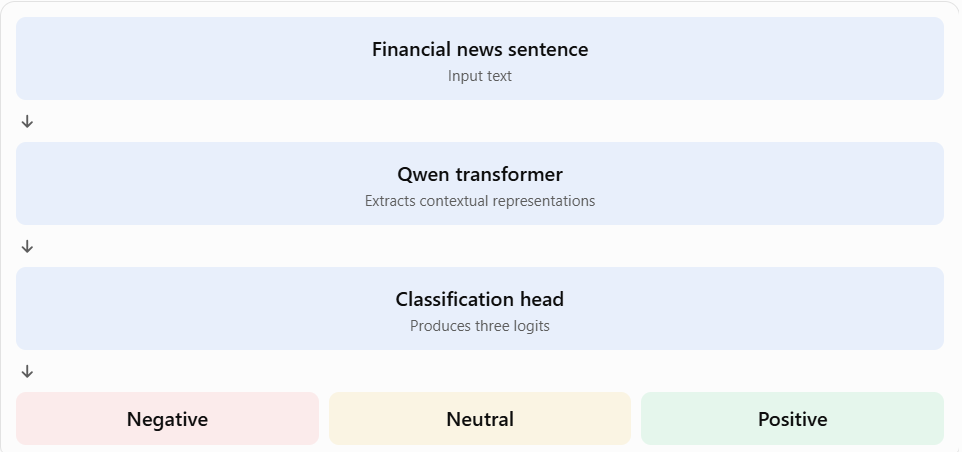


The classification head is newly initialized because we're adapting a pretrained language model to a three-class classification task. We'll train it along with the LoRA adapters.

In [10]:
#Load the quantized Qwen model
from transformers import AutoModelForSequenceClassification

label2id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

id2label = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    label2id=label2id,
    id2label=id2label,
    quantization_config=quantization_config,
    device_map="auto"
)

print("Quantized model loaded successfully!")
print("Model type:", model.config.model_type)
print("Number of labels:", model.config.num_labels)
print("GPU:", torch.cuda.get_device_name(0))

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Quantized model loaded successfully!
Model type: qwen2
Number of labels: 3
GPU: Tesla T4


# Prepare the model for QLoRA

Before adding LoRA, prepare the quantized model for adapter training.

using Hugging Face PEFT's prepare_model_for_kbit_training().

It helps by:
1. Keeping the quantized base model frozen.
2. Preparing certain layers for stable training.
3. Enabling gradient checkpointing to reduce GPU memory usage.
First, let's verify our model's layer names and configure padding.

inspecting q_proj and v_proj:
Inside the transformer:
- q_proj creates Query representations.
- v_proj creates Value representations.
These are components of the attention mechanism.




inserting small trainable LoRA adapters into these layers instead of updating all the original model weights.

In [11]:
# Configure padding
model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False

# Inspect LoRA target layers
target_layers = [
    name for name, module in model.named_modules()
    if name.endswith(("q_proj", "v_proj"))
]

print("Padding token ID:", tokenizer.pad_token_id)
print("\nLoRA target layers:")
for layer in target_layers:
    print(layer)

print("\nClassification head:")
print(model.score)

Padding token ID: 151643

LoRA target layers:
model.layers.0.self_attn.q_proj
model.layers.0.self_attn.v_proj
model.layers.1.self_attn.q_proj
model.layers.1.self_attn.v_proj
model.layers.2.self_attn.q_proj
model.layers.2.self_attn.v_proj
model.layers.3.self_attn.q_proj
model.layers.3.self_attn.v_proj
model.layers.4.self_attn.q_proj
model.layers.4.self_attn.v_proj
model.layers.5.self_attn.q_proj
model.layers.5.self_attn.v_proj
model.layers.6.self_attn.q_proj
model.layers.6.self_attn.v_proj
model.layers.7.self_attn.q_proj
model.layers.7.self_attn.v_proj
model.layers.8.self_attn.q_proj
model.layers.8.self_attn.v_proj
model.layers.9.self_attn.q_proj
model.layers.9.self_attn.v_proj
model.layers.10.self_attn.q_proj
model.layers.10.self_attn.v_proj
model.layers.11.self_attn.q_proj
model.layers.11.self_attn.v_proj
model.layers.12.self_attn.q_proj
model.layers.12.self_attn.v_proj
model.layers.13.self_attn.q_proj
model.layers.13.self_attn.v_proj
model.layers.14.self_attn.q_proj
model.layers.14.s


A few observations:
- Qwen has 24 transformer layers.
- Every layer contains both q_proj and v_proj.
- We have 48 target modules for LoRA adaptation.
- The classification head has 896 input features and 3 output classes.

base model is quantized to 4-bit. Before training, PEFT prepares it for stable adapter training.

Gradient checkpointing also helps reduce GPU memory consumption by recomputing some activations during the backward pass.

In [12]:
#Prepare the model for k-bit training
from peft import (
    prepare_model_for_kbit_training,
    LoraConfig,
    get_peft_model
)

# Prepare the quantized model
model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=True
)

print("Model prepared for k-bit training!")

Model prepared for k-bit training!


In [13]:
#Configure LORA
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="SEQ_CLS",
    target_modules=["q_proj", "v_proj"],
    modules_to_save=["score"]
)

print("LoRA configuration created!")

LoRA configuration created!


In [14]:
#Attach Adapters
model = get_peft_model(model, lora_config)

print("LoRA adapters attached successfully!")

model.print_trainable_parameters()

LoRA adapters attached successfully!
trainable params: 543,360 || all params: 494,578,816 || trainable%: 0.1099


In [15]:
#prepare the financial sentiment dataset
label2id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

In [16]:
#tokenize the data
MAX_LENGTH = 128

def tokenize_data(dataframe):
    return tokenizer(
        dataframe["text"].tolist(),
        truncation=True,
        padding="max_length",
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

train_encodings = tokenize_data(train_df)
val_encodings = tokenize_data(val_df)
test_encodings = tokenize_data(test_df)

print("Tokenization completed!")
print("Training input shape:", train_encodings["input_ids"].shape)
print("Validation input shape:", val_encodings["input_ids"].shape)
print("Testing input shape:", test_encodings["input_ids"].shape)

Tokenization completed!
Training input shape: torch.Size([3868, 128])
Validation input shape: torch.Size([484, 128])
Testing input shape: torch.Size([484, 128])


In [17]:
#convert tokenized data and sentiment labels into PyTorch datasets
from torch.utils.data import TensorDataset

def create_dataset(encodings, dataframe):

    labels = torch.tensor(
        dataframe["sentiment"].map(label2id).values,
        dtype=torch.long
    )

    dataset = TensorDataset(
        encodings["input_ids"],
        encodings["attention_mask"],
        labels
    )

    return dataset


train_dataset = create_dataset(train_encodings, train_df)
val_dataset = create_dataset(val_encodings, val_df)
test_dataset = create_dataset(test_encodings, test_df)

print("PyTorch datasets created successfully!")

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

# Inspect one sample
sample = train_dataset[0]

print("\nInput IDs shape:", sample[0].shape)
print("Attention mask shape:", sample[1].shape)
print("Label:", sample[2].item())
print("Label name:", id2label[sample[2].item()])

PyTorch datasets created successfully!
Training samples: 3868
Validation samples: 484
Testing samples: 484

Input IDs shape: torch.Size([128])
Attention mask shape: torch.Size([128])
Label: 1
Label name: neutral


**Creating DataLoaders**

A DataLoader feeds the model small batches of data instead of sending all 3,868 training samples at once.

We'll use:
- Training batch size: 4
- Validation batch size: 8
- Test batch size: 8
- Shuffle training data only.

In [18]:
from torch.utils.data import DataLoader

BATCH_SIZE = 4
EVAL_BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created successfully!")

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully!
Training batches: 967
Validation batches: 61
Testing batches: 61


In [19]:
#setting training parameters
EPOCHS = 3
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.01

GRADIENT_ACCUMULATION_STEPS = 4

print("Training configuration:")
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)

Training configuration:
Epochs: 3
Learning rate: 0.0002
Weight decay: 0.01
Gradient accumulation: 4


AdamW: Updates the LoRA adapters and classification head.



Learning-rate warmup: Gradually increases the learning rate at the beginning.



Linear decay: Gradually decreases the learning rate towards the end of training.

In [20]:
#Configuring the optimizer and learning-rate scheduler
import math
import torch

# Only parameters marked as trainable will be updated
trainable_parameters = [
    parameter for parameter in model.parameters()
    if parameter.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Calculate total optimizer updates
updates_per_epoch = math.ceil(
    len(train_loader) / GRADIENT_ACCUMULATION_STEPS
)

total_training_steps = updates_per_epoch * EPOCHS

# Use 10% of training steps for learning-rate warmup
warmup_steps = int(0.10 * total_training_steps)

def lr_lambda(current_step):
    if current_step < warmup_steps:
        return float(current_step) / max(1, warmup_steps)

    return max(
        0.0,
        float(total_training_steps - current_step)
        / max(1, total_training_steps - warmup_steps)
    )

scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda
)

print("Optimizer and scheduler configured!")
print("Trainable parameters:", sum(
    p.numel() for p in trainable_parameters
))
print("Updates per epoch:", updates_per_epoch)
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])

Optimizer and scheduler configured!
Trainable parameters: 543360
Updates per epoch: 242
Total training steps: 726
Warmup steps: 72
Initial learning rate: 0.0


Fine-tune the model
Before running training, one important detail: training loop should:
1. Send each batch to the GPU.
2. Perform a forward pass and calculate classification loss.
3. Calculate gradients through backpropagation.
4. Accumulate gradients over four batches.
5. Update LoRA parameters and the classification head.
6. Evaluate on validation data after each epoch.

In [21]:
#fine tune the model
import torch
import numpy as np
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.train()

best_val_f1 = 0.0

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0.0
    optimizer.zero_grad(set_to_none=True)

    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

    for step, batch in enumerate(progress_bar):

        input_ids, attention_mask, labels = [
            tensor.to(device) for tensor in batch
        ]

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        total_loss += loss.item()

        (loss / GRADIENT_ACCUMULATION_STEPS).backward()

        if (step + 1) % GRADIENT_ACCUMULATION_STEPS == 0 or (step + 1) == len(train_loader):
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)

        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = total_loss / len(train_loader)

    # Validation
    model.eval()
    val_predictions = []
    val_actuals = []
    val_loss = 0.0

    with torch.no_grad():

        for batch in val_loader:

            input_ids, attention_mask, labels = [
                tensor.to(device) for tensor in batch
            ]

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            val_loss += outputs.loss.item()

            predictions = torch.argmax(outputs.logits, dim=1)

            val_predictions.extend(predictions.cpu().numpy())
            val_actuals.extend(labels.cpu().numpy())

    val_predictions = np.array(val_predictions)
    val_actuals = np.array(val_actuals)

    val_accuracy = accuracy_score(val_actuals, val_predictions)
    val_macro_f1 = f1_score(
        val_actuals,
        val_predictions,
        average="macro"
    )

    avg_val_loss = val_loss / len(val_loader)

    print(f"\nEpoch {epoch+1}")
    print(f"Training Loss: {avg_train_loss:.4f}")
    print(f"Validation Loss: {avg_val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro F1: {val_macro_f1:.4f}")

    if val_macro_f1 > best_val_f1:

        best_val_f1 = val_macro_f1

        model.save_pretrained(
            "/content/drive/MyDrive/QLoRA_Backup/best_qlora_adapter"
        )

        print("Best model checkpoint saved!")

print("\nFine-tuning completed!")
print("Best Validation Macro F1:", round(best_val_f1, 4))

Epoch 1/3:   0%|          | 0/967 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)



Epoch 1
Training Loss: 1.0733
Validation Loss: 0.4391
Validation Accuracy: 0.8182
Validation Macro F1: 0.7842
Best model checkpoint saved!


Epoch 2/3:   0%|          | 0/967 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)



Epoch 2
Training Loss: 0.3348
Validation Loss: 0.3206
Validation Accuracy: 0.8678
Validation Macro F1: 0.8620
Best model checkpoint saved!


Epoch 3/3:   0%|          | 0/967 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)



Epoch 3
Training Loss: 0.2370
Validation Loss: 0.3233
Validation Accuracy: 0.8616
Validation Macro F1: 0.8478

Fine-tuning completed!
Best Validation Macro F1: 0.862


In [22]:
#restore the best checkpoint
#This loads the saved LoRA weights and classification head from Epoch 2 rather than using the final Epoch 3 weights.
BEST_MODEL_PATH = "/content/drive/MyDrive/QLoRA_Backup/best_qlora_adapter"

import os

print("Checkpoint files:", os.listdir(BEST_MODEL_PATH))

# Load the best saved adapter
model.load_adapter(
    BEST_MODEL_PATH,
    adapter_name="best"
)

# Activate the best adapter
model.set_adapter("best")

model.eval()

print("Active adapter:", model.active_adapters)
print("Best checkpoint restored successfully!")

Checkpoint files: ['README.md', 'adapter_model.safetensors', 'adapter_config.json']
Active adapter: ['best']
Best checkpoint restored successfully!


In [23]:
#final test evalluation
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

model.eval()

all_predictions = []
all_actuals = []

with torch.no_grad():

    for batch in test_loader:

        input_ids, attention_mask, labels = [
            tensor.to(device) for tensor in batch
        ]

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_actuals.extend(labels.cpu().numpy())


# Convert numerical labels into arrays
all_predictions = np.array(all_predictions)
all_actuals = np.array(all_actuals)

# Overall metrics
accuracy = accuracy_score(all_actuals, all_predictions)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        all_actuals,
        all_predictions,
        average="macro",
        zero_division=0
    )
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        all_actuals,
        all_predictions,
        average="weighted",
        zero_division=0
    )
)

print("========== QLoRA TEST RESULTS ==========")

print(f"Accuracy:          {accuracy:.4f}")
print(f"Macro Precision:   {macro_precision:.4f}")
print(f"Macro Recall:      {macro_recall:.4f}")
print(f"Macro F1:          {macro_f1:.4f}")
print(f"Weighted Precision:{weighted_precision:.4f}")
print(f"Weighted Recall:   {weighted_recall:.4f}")
print(f"Weighted F1:       {weighted_f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        all_actuals,
        all_predictions,
        labels=[0, 1, 2],
        target_names=["negative", "neutral", "positive"],
        zero_division=0
    )
)

print("\n========== CONFUSION MATRIX ==========")

cm = confusion_matrix(
    all_actuals,
    all_predictions,
    labels=[0, 1, 2]
)

print(cm)

print("\n========== PREDICTION DISTRIBUTION ==========")

print(
    pd.Series(
        [id2label[x] for x in all_predictions]
    ).value_counts()
)

========== QLoRA TEST RESULTS ==========
Accuracy:          0.8161
Macro Precision:   0.7890
Macro Recall:      0.7925
Macro F1:          0.7907
Weighted Precision:0.8160
Weighted Recall:   0.8161
Weighted F1:       0.8160

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

    negative       0.75      0.77      0.76        61
     neutral       0.85      0.86      0.86       287
    positive       0.77      0.75      0.76       136

    accuracy                           0.82       484
   macro avg       0.79      0.79      0.79       484
weighted avg       0.82      0.82      0.82       484


========== CONFUSION MATRIX ==========
[[ 47  10   4]
 [ 14 246  27]
 [  2  32 102]]

========== PREDICTION DISTRIBUTION ==========
neutral     288
positive    133
negative     63
Name: count, dtype: int64


In [24]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Overall evaluation metrics
metrics = {
    "Accuracy": accuracy_score(all_actuals, all_predictions),
    "Macro Precision": precision_score(
        all_actuals, all_predictions, average="macro"
    ),
    "Macro Recall": recall_score(
        all_actuals, all_predictions, average="macro"
    ),
    "Macro F1": f1_score(
        all_actuals, all_predictions, average="macro"
    ),
    "Weighted Precision": precision_score(
        all_actuals, all_predictions, average="weighted"
    ),
    "Weighted Recall": recall_score(
        all_actuals, all_predictions, average="weighted"
    ),
    "Weighted F1": f1_score(
        all_actuals, all_predictions, average="weighted"
    )
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Score"]
)

metrics_df["Score"] = metrics_df["Score"].round(4)

display(metrics_df)

,Metric,Score
0,Accuracy,0.8161
1,Macro Precision,0.7890
2,Macro Recall,0.7925
3,Macro F1,0.7907
4,Weighted Precision,0.8160
5,Weighted Recall,0.8161
6,Weighted F1,0.8160


In [25]:
report = classification_report(
    all_actuals,
    all_predictions,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    output_dict=True,
    zero_division=0
)

class_report_df = pd.DataFrame(report).transpose()

display(class_report_df.round(4))

,precision,recall,f1-score,support
Negative,0.7460,0.7705,0.7581,61.0000
Neutral,0.8542,0.8571,0.8557,287.0000
Positive,0.7669,0.7500,0.7584,136.0000
accuracy,0.8161,0.8161,0.8161,0.8161
macro avg,0.7890,0.7925,0.7907,484.0000
weighted avg,0.8160,0.8161,0.8160,484.0000


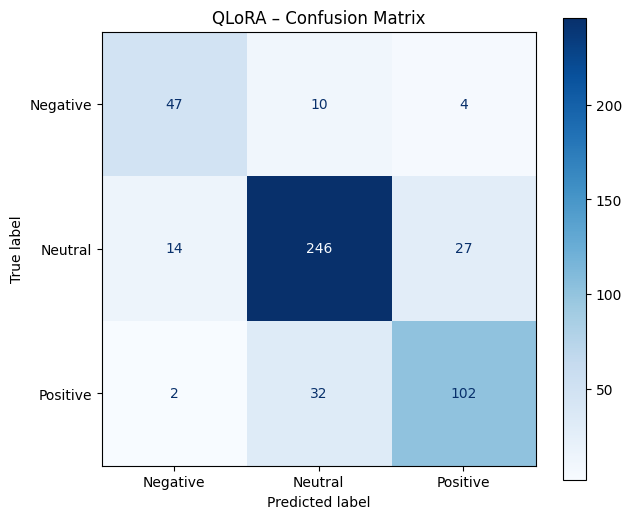

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    all_actuals,
    all_predictions,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=plt.gca()
)

plt.title("QLoRA – Confusion Matrix")
plt.show()

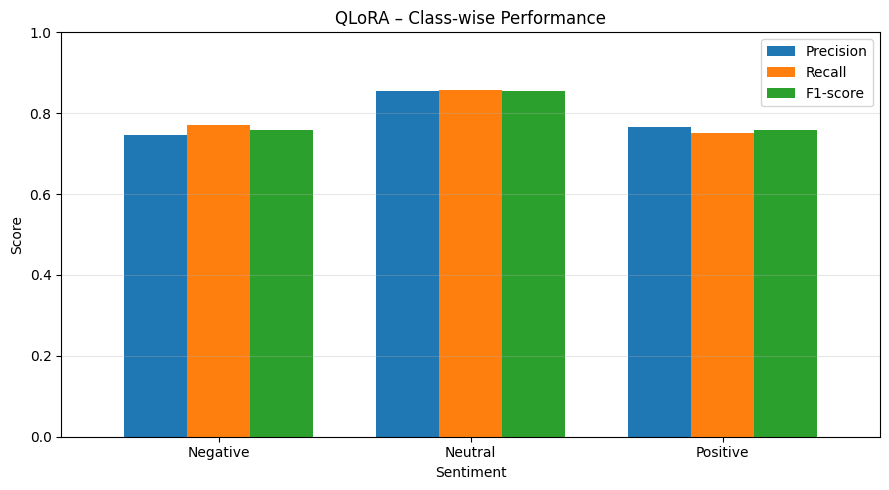

In [27]:
class_metrics = class_report_df.loc[
    ["Negative", "Neutral", "Positive"],
    ["precision", "recall", "f1-score"]
]

class_metrics.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    width=0.75
)

plt.title("QLoRA – Class-wise Performance")
plt.xlabel("Sentiment")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(["Precision", "Recall", "F1-score"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
training_history = pd.DataFrame({
    "Epoch": [1, 2, 3],
    "Training Loss": [1.0733, 0.3348, 0.2370],
    "Validation Loss": [0.4391, 0.3206, 0.3233],
    "Validation Accuracy": [0.8182, 0.8678, 0.8616],
    "Validation Macro F1": [0.7842, 0.8620, 0.8478]
})

display(training_history)

,Epoch,Training Loss,Validation Loss,Validation Accuracy,Validation Macro F1
0,1,1.0733,0.4391,0.8182,0.7842
1,2,0.3348,0.3206,0.8678,0.8620
2,3,0.2370,0.3233,0.8616,0.8478


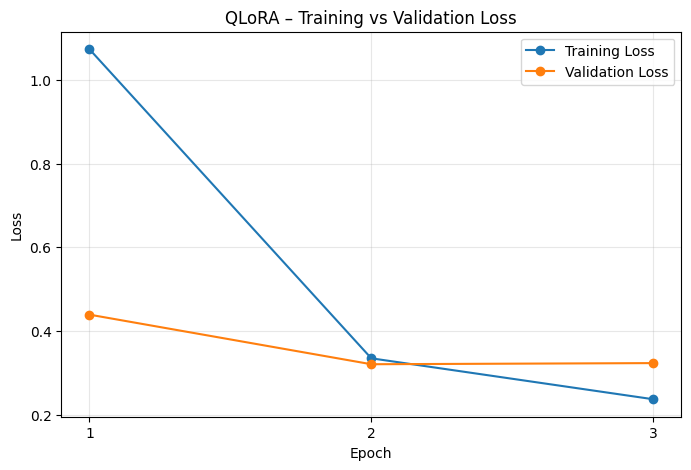

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(
    training_history["Epoch"],
    training_history["Training Loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    training_history["Epoch"],
    training_history["Validation Loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("QLoRA – Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks([1, 2, 3])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

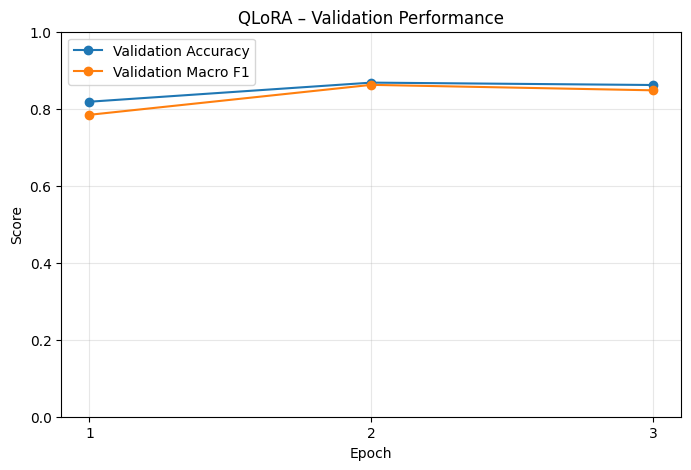

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    training_history["Epoch"],
    training_history["Validation Accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.plot(
    training_history["Epoch"],
    training_history["Validation Macro F1"],
    marker="o",
    label="Validation Macro F1"
)

plt.title("QLoRA – Validation Performance")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.xticks([1, 2, 3])
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [32]:
import os

# Create output folder
output_dir = "/content/drive/MyDrive/QLoRA_Backup/Results"
os.makedirs(output_dir, exist_ok=True)

# Save evaluation metrics
metrics_df.to_csv(
    f"{output_dir}/overall_metrics.csv",
    index=False
)

# Save classification report
class_report_df.to_csv(
    f"{output_dir}/class_report.csv"
)

# Save confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=["Actual_Negative", "Actual_Neutral", "Actual_Positive"],
    columns=["Predicted_Negative", "Predicted_Neutral", "Predicted_Positive"]
)

cm_df.to_csv(f"{output_dir}/confusion_matrix.csv")

# Save training history
training_history.to_csv(
    f"{output_dir}/training_history.csv",
    index=False
)
# Convert numerical labels into sentiment names
actual_labels = pd.Series(
    [id2label[int(x)] for x in all_actuals]
)

predicted_labels = pd.Series(
    [id2label[int(x)] for x in all_predictions]
)

# Save individual predictions
predictions_df = pd.DataFrame({
    "Actual": actual_labels,
    "Predicted": predicted_labels
})

predictions_df.to_csv(
    f"{output_dir}/test_predictions.csv",
    index=False
)

# Save individual predictions
predictions_df = pd.DataFrame({
    "Actual": actual_labels,
    "Predicted": predicted_labels
})

predictions_df.to_csv(
    f"{output_dir}/test_predictions.csv",
    index=False
)

# Save approach-independent QLoRA metrics in Excel
with pd.ExcelWriter(
    f"{output_dir}/QLoRA_Complete_Evaluation.xlsx"
) as writer:

    metrics_df.to_excel(writer, sheet_name="Overall Metrics", index=False)
    class_report_df.to_excel(writer, sheet_name="Class Report")
    cm_df.to_excel(writer, sheet_name="Confusion Matrix")
    training_history.to_excel(writer, sheet_name="Training History", index=False)
    predictions_df.to_excel(writer, sheet_name="Test Predictions", index=False)

print("All evaluation results saved successfully!")
print("Location:", output_dir)

All evaluation results saved successfully!
Location: /content/drive/MyDrive/QLoRA_Backup/Results
